<a href="https://colab.research.google.com/github/iclalkececi/ai-hr-analytics-system/blob/k3-baslik/proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Veri Madenciliği Projesi – CV Değerlendirme ve Tükenmişlik Riski
Hücreleri **yukarıdan aşağıya sırayla** çalıştırın (her hücrenin solundaki ▶ düğmesi). Her oturumda Hücre 1'den başlayın.

## Hücre 1 – Kurulum ve Drive bağlantısı
Gerekli kütüphaneleri kurar, Drive'ı bağlar ve proje klasörünü bulur. Drive izni isteyen pencerede hesabınızı seçip izin verin. Her Colab oturumunun başında bir kez çalıştırılır.

In [ ]:
!pip install -q pdfplumber sentence-transformers
from google.colab import drive
drive.mount("/content/drive")

import glob, os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

adaylar = glob.glob("/content/drive/MyDrive/veri madencili*")
if not adaylar:
    raise FileNotFoundError("Proje klasörü bulunamadı. Klasöre 'Drive'ım'a kısayol ekle' yaptınız mı?")
KLASOR = adaylar[0]
CV_K   = f"{KLASOR}/CV_Proje_Verileri"
BR_K   = f"{KLASOR}/Burnout_Verileri"
CIKTI  = f"{KLASOR}/ciktilar"
os.makedirs(CIKTI, exist_ok=True)
print("Proje klasörü:", KLASOR)

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/veri madenciliği proje


## Hücre 2 – Verileri okuma ve kontrol
Üç tabloyu okur ve boyutlarını yazdırır. Beklenen çıktılar: CV tablosu yaklaşık (2484, 4), Burnout (22750, 9), İlanlar (4, 4).

In [ ]:
cv      = pd.read_csv(glob.glob(f"{CV_K}/Resume/*.csv")[0])
burnout = pd.read_csv(f"{BR_K}/train.csv")
ilanlar = pd.read_csv(f"{KLASOR}/ilanlar.csv")

print("CV tablosu :", cv.shape)
print("Burnout    :", burnout.shape)
print("İlanlar    :", ilanlar.shape)
print("\nMeslek gruplarına göre CV sayısı:")
print(cv["Category"].value_counts())

CV tablosu : (2484, 4)
Burnout    : (22750, 9)
İlanlar    : (4, 4)

Meslek gruplarına göre CV sayısı:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


## Hücre 3 – Çalışılacak PDF'leri seçme
2.484 PDF'in hepsini okumak uzun sürer. Bu hücre ilanlardaki mesleklerden 40'ar, diğer mesleklerden 5'er CV seçer (yaklaşık 260 CV). Rastgele seçim her seferinde aynı sonucu verir (random seed = 42).

In [ ]:
ILGILI = [m.upper() for m in ilanlar["beklenen_meslek"]]
rng = np.random.default_rng(42)
secilen = []
for klasor in sorted(glob.glob(f"{CV_K}/data/**/", recursive=True)):
    meslek = os.path.basename(os.path.normpath(klasor)).upper()
    dosyalar = sorted(glob.glob(f"{klasor}*.pdf"))
    if not dosyalar:
        continue
    adet = 40 if meslek in ILGILI else 5
    secilen += list(rng.choice(dosyalar, size=min(adet, len(dosyalar)), replace=False))
print(len(secilen), "PDF seçildi")

260 PDF seçildi


## Hücre 4 – IDP: PDF'ten yazı ve bilgi çıkarma
Her PDF için yazıyı çıkarır, temizler, becerileri bulur ve CV'de geçen yıllardan yaklaşık deneyim süresini hesaplar. Sonuç tablosu ciktilar klasörüne cv_tablosu.csv olarak kaydedilir. 260 CV için 2–5 dakika sürebilir.

In [ ]:
import pdfplumber

def pdf_yazisi(yol):
    try:
        with pdfplumber.open(yol) as pdf:
            return " ".join((s.extract_text() or "") for s in pdf.pages)
    except Exception as hata:
        print("Okunamadı:", yol, hata)
        return ""

def temizle(yazi):
    return re.sub(r"\s+", " ", yazi).strip()

BECERILER = ["python", "sql", "excel", "power bi", "tableau", "java", "c++",
             "machine learning", "data analysis", "reporting", "accounting",
             "budgeting", "tax", "payroll", "recruitment", "onboarding",
             "communication", "leadership", "negotiation", "crm", "sales",
             "customer service", "project management", "marketing",
             # --- Gün 4'te eklenenler ---
             "quickbooks", "sap", "general ledger", "reconciliation", "budget",
             "journal entries", "auditing", "audit",
             "advertising", "scheduling", "time management",
             "employee relations", "training and development",
             "performance management", "benefits administration", "hris",
             "cloud computing", "network management", "database",
             "troubleshooting", "strategic planning",
             ]

def beceri_bul(yazi):
    k = yazi.lower()
    return [b for b in BECERILER if re.search(r"(?<![a-z])" + re.escape(b) + r"(?![a-z])", k)]

def yaklasik_deneyim(yazi):
    # CV'de geçen en eski ve en yeni yıl arasındaki fark (kaba bir tahmin)
    yillar = [int(y) for y in re.findall(r"\b(19[89]\d|20[0-2]\d)\b", yazi)]
    return min(max(yillar) - min(yillar), 40) if len(yillar) >= 2 else 0

satirlar = []
for i, yol in enumerate(secilen, 1):
    yazi = temizle(pdf_yazisi(yol))
    beceriler = beceri_bul(yazi)
    satirlar.append({
        "id": os.path.splitext(os.path.basename(yol))[0],
        "meslek": os.path.basename(os.path.dirname(yol)).upper(),
        "karakter_sayisi": len(yazi),
        "beceri_sayisi": len(beceriler),
        "beceriler": ", ".join(beceriler),
        "deneyim_yil": yaklasik_deneyim(yazi),
        "yazi": yazi,
    })
    if i % 50 == 0:
        print(i, "CV işlendi")

cvt = pd.DataFrame(satirlar)
print(f"Yazısı okunabilen CV oranı: %{(cvt.karakter_sayisi > 200).mean() * 100:.0f}")
cvt.to_csv(f"{CIKTI}/cv_tablosu.csv", index=False)
cvt[["id", "meslek", "karakter_sayisi", "beceri_sayisi", "deneyim_yil", "beceriler"]].head(10)

50 CV işlendi
100 CV işlendi
150 CV işlendi
200 CV işlendi
250 CV işlendi
Yazısı okunabilen CV oranı: %100


,id,meslek,karakter_sayisi,beceri_sayisi,deneyim_yil,beceriler
0,49997097,ACCOUNTANT,5178,9,10,"excel, reporting, accounting, tax, payroll, qu..."
1,12780508,ACCOUNTANT,7470,10,12,"excel, reporting, accounting, communication, s..."
2,39115899,ACCOUNTANT,4786,12,10,"sql, excel, data analysis, accounting, crm, cu..."
3,14224370,ACCOUNTANT,3115,9,9,"excel, accounting, tax, payroll, communication..."
4,78403342,ACCOUNTANT,6269,15,15,"excel, reporting, accounting, payroll, communi..."
5,35554162,ACCOUNTANT,5107,8,11,"reporting, accounting, budgeting, payroll, com..."
6,30304575,ACCOUNTANT,7937,14,8,"excel, reporting, accounting, budgeting, tax, ..."
7,13072019,ACCOUNTANT,6056,6,20,"accounting, payroll, project management, sap, ..."
8,59403481,ACCOUNTANT,5727,13,17,"excel, reporting, accounting, tax, payroll, co..."
9,24294778,ACCOUNTANT,8983,13,14,"excel, accounting, payroll, communication, sal..."


## Hücre 5 – CV ile ilan benzerliği (SBERT)
CV'leri ve ilanları sayılara çevirip benzerlik puanını (0–1) hesaplar. Her ilan için en uygun 10 CV'yi ve bunların yüzde kaçının beklenen meslekten geldiğini gösterir. İlk çalıştırmada model indirilir (1–2 dakika).

In [ ]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer("all-MiniLM-L6-v2")
cv_vek   = model.encode(cvt["yazi"].tolist(), convert_to_tensor=True, show_progress_bar=True)
ilan_vek = model.encode(ilanlar["metin"].tolist(), convert_to_tensor=True)
puan = util.cos_sim(ilan_vek, cv_vek).cpu().numpy()     # satır = ilan, sütun = CV

for i in range(len(ilanlar)):
    ilan = ilanlar.iloc[i]
    cvt[f"uyum_{ilan['ilan_id']}"] = puan[i]
    ilk10 = cvt.sort_values(f"uyum_{ilan['ilan_id']}", ascending=False).head(10)
    dogru = (ilk10["meslek"] == str(ilan["beklenen_meslek"]).upper()).mean()
    print(f"\n{ilan['pozisyon']}: ilk 10 CV'nin %{dogru * 100:.0f}'i beklenen meslekten")
    print(ilk10[["id", "meslek", f"uyum_{ilan['ilan_id']}"]].round(3).to_string(index=False))

cvt["en_iyi_uyum"] = puan.max(axis=0)
cvt.drop(columns="yazi").to_csv(f"{CIKTI}/cv_benzerlik.csv", index=False)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]


Data Analyst: ilk 10 CV'nin %20'i beklenen meslekten
      id                 meslek  uyum_1
37242217 INFORMATION-TECHNOLOGY   0.481
37997506             ACCOUNTANT   0.456
20237244 INFORMATION-TECHNOLOGY   0.431
26975573             ACCOUNTANT   0.425
77439230               ADVOCATE   0.424
51769822                     HR   0.424
59403481             ACCOUNTANT   0.420
25547145             ACCOUNTANT   0.412
88651471       PUBLIC-RELATIONS   0.412
29839396                BANKING   0.410

HR Specialist: ilk 10 CV'nin %100'i beklenen meslekten
      id meslek  uyum_2
11847784     HR   0.726
51769822     HR   0.708
18422164     HR   0.700
14256329     HR   0.697
24184357     HR   0.695
12786012     HR   0.673
13520837     HR   0.672
18316239     HR   0.652
11480899     HR   0.652
26202430     HR   0.650

Accountant: ilk 10 CV'nin %100'i beklenen meslekten
      id     meslek  uyum_3
14449423 ACCOUNTANT   0.738
21794875 ACCOUNTANT   0.696
78403342 ACCOUNTANT   0.695
21338490 ACCOUNTANT  

In [ ]:
# Hücre 5a – 4 ilan için iki yöntemin karşılaştırması (K1–K4)
for no in ilanlar.ilan_id:
    ilan = ilanlar[ilanlar.ilan_id == no].iloc[0]
    hedef = ilan.beklenen_meslek.upper()
    ilan_beceri = beceri_bul(ilan.metin)
    cvt["beceri_uyum"] = cvt.beceriler.apply(
        lambda b: len(set(b.split(", ")) & set(ilan_beceri)) / max(len(ilan_beceri), 1))
    ilk10_sbert  = cvt.sort_values(f"uyum_{no}", ascending=False).head(10)
    ilk10_beceri = cvt.sort_values("beceri_uyum", ascending=False).head(10)
    print(f"{ilan.pozisyon:25s} SBERT: %{(ilk10_sbert.meslek == hedef).mean()*100:.0f}  |  "
          f"Beceri: %{(ilk10_beceri.meslek == hedef).mean()*100:.0f}")

Data Analyst              SBERT: %20  |  Beceri: %10
HR Specialist             SBERT: %100  |  Beceri: %100
Accountant                SBERT: %100  |  Beceri: %90
Sales Representative      SBERT: %90  |  Beceri: %50


## Hücre 6 – Tükenmişlik verisini tanıma
Sütunların özetini, boş hücre sayılarını ve grafiklerini gösterir. Çıkan grafikleri ve boş hücre sayılarını rapora ekleyin.

       Designation  Resource Allocation  Mental Fatigue Score  Burn Rate
count     22750.00             21369.00              20633.00   21626.00
mean          2.18                 4.48                  5.73       0.45
std           1.14                 2.05                  1.92       0.20
min           0.00                 1.00                  0.00       0.00
25%           1.00                 3.00                  4.60       0.31
50%           2.00                 4.00                  5.90       0.45
75%           3.00                 6.00                  7.10       0.59
max           5.00                10.00                 10.00       1.00

Boş hücre sayıları:
Employee ID                0
Date of Joining            0
Gender                     0
Company Type               0
WFH Setup Available        0
Designation                0
Resource Allocation     1381
Mental Fatigue Score    2117
Burn Rate               1124
dtype: int64


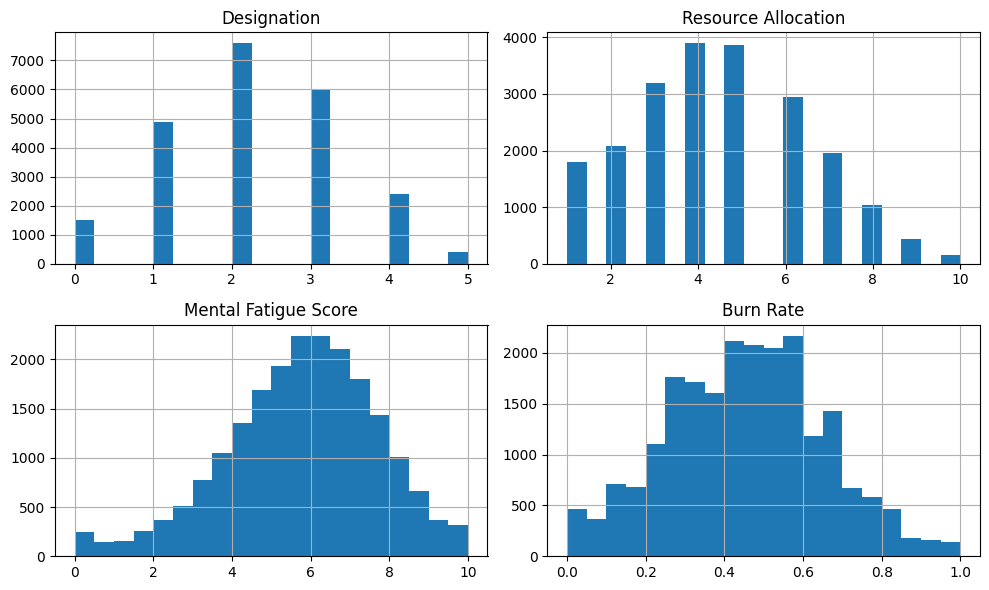

In [ ]:
print(burnout.describe().round(2))
print("\nBoş hücre sayıları:")
print(burnout.isna().sum())
burnout.hist(figsize=(10, 6), bins=20)
plt.tight_layout(); plt.show()

## Hücre 7 – Temizleme ve eğitim/test ayırma
Tükenmişlik puanı boş satırları siler, Evet/Hayır ve Hizmet/Ürün sütunlarını 1/0'a çevirir, veriyi %80 eğitim ve %20 test olarak ayırır. Boşlukları yalnızca eğitim verisinin ortanca değeriyle doldurur (veri sızıntısını önlemek için).

In [ ]:
from sklearn.model_selection import train_test_split

df = burnout.dropna(subset=["Burn Rate"]).copy()
df["WFH"]    = (df["WFH Setup Available"] == "Yes").astype(int)   # evden çalışma: 1 = var
df["Hizmet"] = (df["Company Type"] == "Service").astype(int)       # şirket türü: 1 = hizmet

GIRDILER = ["Resource Allocation", "Designation", "WFH", "Hizmet", "Mental Fatigue Score"]
X, y = df[GIRDILER], df["Burn Rate"]
X_eg, X_te, y_eg, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

ortanca = X_eg.median()
X_eg, X_te = X_eg.fillna(ortanca), X_te.fillna(ortanca)
print("Eğitim:", X_eg.shape, " Test:", X_te.shape)

Eğitim: (17300, 5)  Test: (4326, 5)


## Hücre 8 – Regresyon
İki model kurar: A yorgunluk puanını içerir, B içermez (B yalnızca işe almadan önce bilinebilecek bilgileri kullanır). Tabloda coef = beta, P>|t| = p-değeri. Test verisinde MAE ve R² ile basit karşılaştırma modelinin hatası da yazdırılır.

In [ ]:
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, r2_score

def regresyon(sutunlar, baslik):
    m = sm.OLS(y_eg, sm.add_constant(X_eg[sutunlar])).fit()
    tahmin = m.predict(sm.add_constant(X_te[sutunlar]))
    print(f"\n===== {baslik} =====")
    print(m.summary().tables[1])
    print(f"Test MAE = {mean_absolute_error(y_te, tahmin):.3f}   Test R² = {r2_score(y_te, tahmin):.3f}")
    return m

ISE_ALIM = ["Resource Allocation", "Designation", "WFH", "Hizmet"]
model_A = regresyon(GIRDILER, "Model A: yorgunluk puanı DAHİL")
model_B = regresyon(ISE_ALIM, "Model B: yorgunluk puanı YOK")
taban = mean_absolute_error(y_te, np.full(len(y_te), y_eg.mean()))
print(f"\nBasit karşılaştırma (herkese ortalamayı tahmin et) MAE = {taban:.3f}")


===== Model A: yorgunluk puanı DAHİL =====
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.0833      0.002    -37.778      0.000      -0.088      -0.079
Resource Allocation      0.0315      0.001     53.338      0.000       0.030       0.033
Designation              0.0087      0.001      9.468      0.000       0.007       0.010
WFH                     -0.0173      0.001    -15.152      0.000      -0.019      -0.015
Hizmet                   0.0003      0.001      0.219      0.827      -0.002       0.002
Mental Fatigue Score     0.0671      0.000    151.161      0.000       0.066       0.068
Test MAE = 0.054   Test R² = 0.867

===== Model B: yorgunluk puanı YOK =====
                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

## Hücre 9 – Karar ağacı ve entropi
Tükenmişlik puanı 0,5 ve üzeri olanları 'yüksek risk' sayar, entropi kullanan 3 seviyeli bir karar ağacı kurar. Başarı ölçülerini, ağacın çizimini ve ağacın ilk sorusu için elle hesaplanan bilgi kazancını gösterir.

Doğruluk  : 0.85
Kesinlik  : 0.78
Yakalama  : 0.87
F1        : 0.83
Karmaşıklık matrisi (satır = gerçek, sütun = tahmin):
[[2073  435]
 [ 232 1586]]


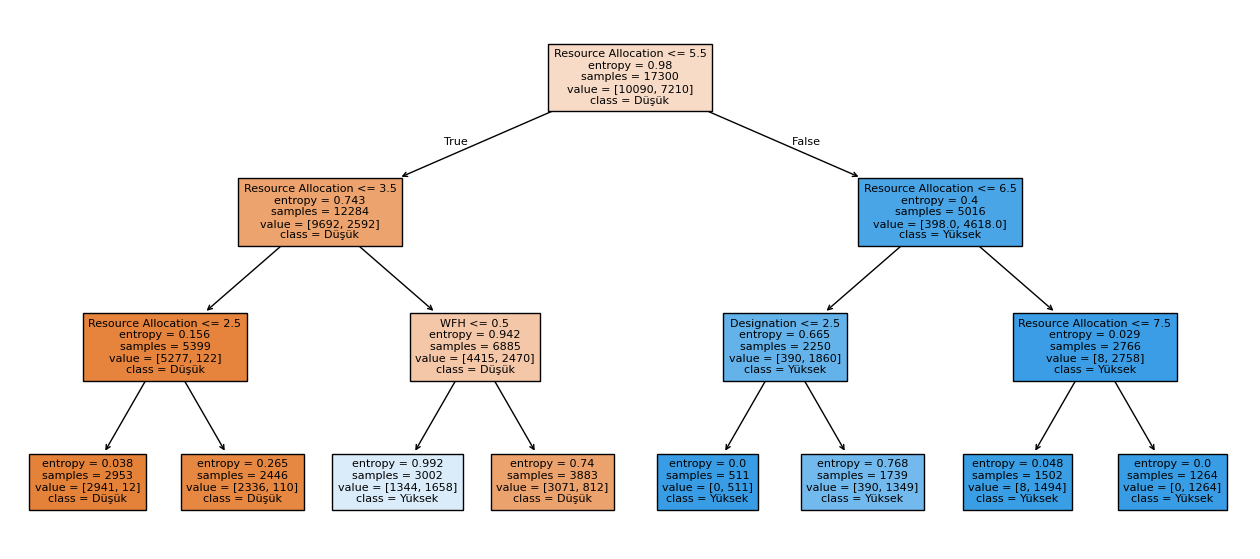


İlk soru: 'Resource Allocation <= 5.5 mi?'
Önceki entropi = 0.980  Sonraki entropi = 0.644  Bilgi kazancı = 0.336


In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

ESIK = 0.5
s_eg, s_te = (y_eg >= ESIK).astype(int), (y_te >= ESIK).astype(int)
agac = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42).fit(X_eg[ISE_ALIM], s_eg)
t = agac.predict(X_te[ISE_ALIM])

print(f"Doğruluk  : {accuracy_score(s_te, t):.2f}")
print(f"Kesinlik  : {precision_score(s_te, t, zero_division=0):.2f}")
print(f"Yakalama  : {recall_score(s_te, t):.2f}")
print(f"F1        : {f1_score(s_te, t):.2f}")
print("Karmaşıklık matrisi (satır = gerçek, sütun = tahmin):")
print(confusion_matrix(s_te, t))

plt.figure(figsize=(16, 7))
plot_tree(agac, feature_names=ISE_ALIM, class_names=["Düşük", "Yüksek"], filled=True, fontsize=8)
plt.show()

def entropi(seri):
    p = seri.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum())

kok_sutun, kok_esik = ISE_ALIM[agac.tree_.feature[0]], agac.tree_.threshold[0]
sol, sag = s_eg[X_eg[kok_sutun] <= kok_esik], s_eg[X_eg[kok_sutun] > kok_esik]
once  = entropi(s_eg)
sonra = len(sol) / len(s_eg) * entropi(sol) + len(sag) / len(s_eg) * entropi(sag)
print(f"\nİlk soru: '{kok_sutun} <= {kok_esik:.1f} mi?'")
print(f"Önceki entropi = {once:.3f}  Sonraki entropi = {sonra:.3f}  Bilgi kazancı = {once - sonra:.3f}")

In [ ]:
# Hücre 9a – Farklı risk sınırlarının denenmesi (K4)
for esik in [0.4, 0.5, 0.6]:
    s_eg2, s_te2 = (y_eg >= esik).astype(int), (y_te >= esik).astype(int)
    agac2 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42).fit(X_eg[ISE_ALIM], s_eg2)
    t2 = agac2.predict(X_te[ISE_ALIM])
    print(f"Sınır {esik}: yüksek riskli oranı %{s_te2.mean()*100:.0f} | "
          f"doğruluk {accuracy_score(s_te2, t2):.2f} | kesinlik {precision_score(s_te2, t2, zero_division=0):.2f} | "
          f"yakalama {recall_score(s_te2, t2):.2f} | F1 {f1_score(s_te2, t2):.2f}")

Sınır 0.4: yüksek riskli oranı %62 | doğruluk 0.80 | kesinlik 0.80 | yakalama 0.90 | F1 0.85
Sınır 0.5: yüksek riskli oranı %42 | doğruluk 0.85 | kesinlik 0.78 | yakalama 0.87 | F1 0.83
Sınır 0.6: yüksek riskli oranı %24 | doğruluk 0.85 | kesinlik 0.78 | yakalama 0.52 | F1 0.63


In [ ]:
# Hücre 9b – Entropi hesabı için sayılar (K3)
print("Tüm eğitim verisi (0 = düşük, 1 = yüksek):"); print(s_eg.value_counts())
print("\nSol grup (soruya EVET):");  print(sol.value_counts())
print("\nSağ grup (soruya HAYIR):"); print(sag.value_counts())

Tüm eğitim verisi (0 = düşük, 1 = yüksek):
Burn Rate
0    10090
1     7210
Name: count, dtype: int64

Sol grup (soruya EVET):
Burn Rate
0    9692
1    2592
Name: count, dtype: int64

Sağ grup (soruya HAYIR):
Burn Rate
1    4618
0     398
Name: count, dtype: int64


## Hücre 10 – 3/6/9/12. ay performansı (SENTETİK)
Gerçek CV'lerden gelen uyum puanı ve deneyim kullanılır; mülakat notu ile 3/6/9/12. ay puanları kurallarla üretilir. Her ay için regresyon kurulur ve R² karşılaştırılır. Sonuç bizim koyduğumuz kuralı yansıtır, gerçek bir bulgu değildir.

In [ ]:
rng = np.random.default_rng(7)
perf = cvt[["id", "meslek", "en_iyi_uyum", "deneyim_yil", "beceri_sayisi"]].copy()
n = len(perf)
perf["mulakat"] = rng.integers(1, 6, n)                                      # SENTETİK
uyum = (perf.en_iyi_uyum - perf.en_iyi_uyum.min()) / (perf.en_iyi_uyum.max() - perf.en_iyi_uyum.min())  # normalizasyon
deneyim = perf.deneyim_yil.clip(0, 15) / 15

# KURAL: CV'nin etkisi zamanla azalır, belirsizlik artar
for ay, etki, belirsizlik in [(3, 1.0, 0.3), (6, 0.8, 0.4), (9, 0.6, 0.5), (12, 0.4, 0.6)]:
    perf[f"perf_{ay}"] = (2 + 1.3 * (1 - etki) + etki * (1.5 * uyum + 0.8 * deneyim)
                          + 0.15 * perf.mulakat + rng.normal(0, belirsizlik, n)).clip(1, 5).round(1)

Xp = sm.add_constant(perf[["en_iyi_uyum", "deneyim_yil", "mulakat"]])
print("SENTETİK VERİ – sonuçlar yalnızca yöntemi göstermek içindir")
for ay in [3, 6, 9, 12]:
    print(f"{ay:>2}. ay   R² = {sm.OLS(perf[f'perf_{ay}'], Xp).fit().rsquared:.2f}")
perf.to_csv(f"{CIKTI}/SENTETIK_performans.csv", index=False)

SENTETİK VERİ – sonuçlar yalnızca yöntemi göstermek içindir
 3. ay   R² = 0.68
 6. ay   R² = 0.42
 9. ay   R² = 0.23
12. ay   R² = 0.17


## Hücre 11 – Köprü: aday + ilan için tükenmişlik senaryosu
Hücre 8'deki Model B'yi (işe almadan önce bilinen bilgiler) kullanarak, bir adayın bir ilanın koşullarında çalışması hâlinde benzer çalışanların ortalama tükenmişlik puanını tahmin eder. Kıdem seviyesi deneyimden varsayımla hesaplanır. Bu kişiye özel bir tahmin değil, bir senaryodur.

In [ ]:
def burnout_senaryosu(gunluk_saat, evden_calisma, hizmet_sirketi, deneyim_yil):
    kidem = int(np.clip(deneyim_yil // 3, 0, 5))          # VARSAYIM: her 3 yıl = 1 kıdem seviyesi
    x = pd.DataFrame([{"const": 1.0, "Resource Allocation": gunluk_saat, "Designation": kidem,
                       "WFH": int(evden_calisma), "Hizmet": int(hizmet_sirketi)}])
    return float(np.clip(model_B.predict(x[model_B.params.index])[0], 0, 1)), kidem

aday = cvt.sort_values("en_iyi_uyum", ascending=False).iloc[0]
for saat, wfh in [(6, True), (9, False)]:
    risk, kidem = burnout_senaryosu(saat, wfh, True, aday["deneyim_yil"])
    print(f"Aday {aday['id']} | günde {saat} saat | evden çalışma: {'var' if wfh else 'yok'} "
          f"| kıdem {kidem} → tahmini tükenmişlik puanı {risk:.2f}  (SENARYO)")

Aday 14449423 | günde 6 saat | evden çalışma: var | kıdem 5 → tahmini tükenmişlik puanı 0.60  (SENARYO)
Aday 14449423 | günde 9 saat | evden çalışma: yok | kıdem 5 → tahmini tükenmişlik puanı 0.85  (SENARYO)


In [ ]:
# Hücre 11a – Köprü senaryoları (K1)
# Her ilanın çalışma koşulları (VARSAYIM)
kosullar = {1: (8, True, False), 2: (8, False, True), 3: (9, False, True), 4: (10, False, True)}
#            ilan_id: (günlük saat, evden çalışma var mı, hizmet şirketi mi)

for ilan_id, (saat, wfh, hizmet) in kosullar.items():
    en_uygun = cvt.sort_values(f"uyum_{ilan_id}", ascending=False).iloc[0]
    for s in [saat, saat - 2]:
        risk, kidem = burnout_senaryosu(s, wfh, hizmet, en_uygun["deneyim_yil"])
        print(f"İlan {ilan_id} | aday {en_uygun['id']} | günde {s} saat | kıdem {kidem} → {risk:.2f}")

İlan 1 | aday 37242217 | günde 8 saat | kıdem 5 → 0.75
İlan 1 | aday 37242217 | günde 6 saat | kıdem 5 → 0.60
İlan 2 | aday 11847784 | günde 8 saat | kıdem 5 → 0.78
İlan 2 | aday 11847784 | günde 6 saat | kıdem 5 → 0.63
İlan 3 | aday 14449423 | günde 9 saat | kıdem 5 → 0.85
İlan 3 | aday 14449423 | günde 7 saat | kıdem 5 → 0.70
İlan 4 | aday 25315791 | günde 10 saat | kıdem 2 → 0.86
İlan 4 | aday 25315791 | günde 8 saat | kıdem 2 → 0.72


## Hücre 12 – Test case'leri (Gereksinim ve Test Dokümanı, Bölüm 6)

In [ ]:
# Hücre 12 – Test case'leri (Gereksinim ve Test Dokümanı, Bölüm 6)
print("TC-02:", beceri_bul("Advanced Excel and SQL skills"))
print("TC-03:", beceri_bul("excellent communication skills"))
print("TC-04:", beceri_bul("handled sales tax filings"))
print("TC-05:", yaklasik_deneyim("Accountant 2010 - 2018"))
uy = [c for c in cvt.columns if c.startswith("uyum_")]
print("TC-06:", round(cvt[uy].min().min(), 3), "–", round(cvt[uy].max().max(), 3))

TC-02: ['sql', 'excel']
TC-03: ['communication']
TC-04: ['tax', 'sales']
TC-05: 8
TC-06: 0.007 – 0.738
